
# EDA — AllLife Communications Telecom Churn

**Key analytical guardrails:**
- **_churn_category_** and **_churn_reason_** are post-outcome fields, so they willl be excluded from predictors.
- **_Joined_** customers are excluded from the modelling population.
- All billing fields are cumulative end-of-quarter snapshots.

In [14]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "config" / "config.yaml").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import logging
import sqlite3

import matplotlib
#matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.data.loader import load_config, load_modeling_dataset

logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger(__name__)


sns.set_theme(style="whitegrid", palette="muted")
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = PROJECT_ROOT / "config" / "config.yaml"
config = load_config(CONFIG_PATH)
DB_PATH = (PROJECT_ROOT / config["data"]["db_path"]).resolve()

In [34]:
conn = sqlite3.connect(DB_PATH)
df_all = pd.read_sql_query("""
    SELECT * FROM customers
""", conn)
conn.close()
df_all.head()

,customer_id,gender,age,married,zip_code,number_of_referrals,tenure_in_months
0,0002-ORFBO,Female,37,Yes,93225,2,9
1,0003-MKNFE,Male,46,No,91206,0,9
2,0004-TLHLJ,Male,50,No,92627,0,4
3,0011-IGKFF,Male,78,Yes,94553,1,13
4,0013-EXCHZ,Female,75,Yes,93010,3,3


In [35]:
conn = sqlite3.connect(DB_PATH)
df_all = pd.read_sql_query("""
    SELECT * FROM service_features
""", conn)
conn.close()
df_all.head()

,customer_id,phone_service,avg_monthly_long_distance_charges,multiple_lines,internet_service,internet_type,avg_monthly_gb_download,streaming_tv,streaming_movies,streaming_music,unlimited_data
0,0002-ORFBO,Yes,42.39,No,Yes,Cable,16.0,Yes,No,No,Yes
1,0003-MKNFE,Yes,10.69,Yes,Yes,Cable,10.0,No,Yes,Yes,No
2,0004-TLHLJ,Yes,33.65,No,Yes,Fiber Optic,30.0,No,No,No,Yes
3,0011-IGKFF,Yes,27.82,No,Yes,Fiber Optic,4.0,Yes,Yes,No,Yes
4,0013-EXCHZ,Yes,7.38,No,Yes,Fiber Optic,11.0,Yes,No,No,Yes


In [36]:
conn = sqlite3.connect(DB_PATH)
df_all = pd.read_sql_query("""
    SELECT * FROM billing_features
""", conn)
conn.close()
df_all.head()

,customer_id,payment_method,total_charges,total_refunds,total_extra_data_charges,total_long_distance_charges,total_revenue
0,0002-ORFBO,Credit Card,593.30,0.00,0.0,381.51,974.81
1,0003-MKNFE,Credit Card,542.40,38.33,10.0,96.21,610.28
2,0004-TLHLJ,Bank Withdrawal,280.85,0.00,0.0,134.60,415.45
3,0011-IGKFF,Bank Withdrawal,1237.85,0.00,0.0,361.66,1599.51
4,0013-EXCHZ,Credit Card,267.40,0.00,0.0,22.14,289.54


In [37]:
conn = sqlite3.connect(DB_PATH)
df_all = pd.read_sql_query("""
    SELECT * FROM churn_outcomes
""", conn)
conn.close()
df_all.head()

,customer_id,customer_status,churn_category,churn_reason
0,0002-ORFBO,Stayed,NaN,NaN
1,0003-MKNFE,Stayed,NaN,NaN
2,0004-TLHLJ,Churned,Competitor,Competitor had better devices
3,0011-IGKFF,Churned,Dissatisfaction,Product dissatisfaction
4,0013-EXCHZ,Churned,Dissatisfaction,Network reliability


In [38]:
conn = sqlite3.connect(DB_PATH)
df_all = pd.read_sql_query("""
    SELECT * FROM zip_population
""", conn)
conn.close()
df_all.head()

,zip_code,population
0,90001,54492
1,90002,44586
2,90003,58198
3,90004,67852
4,90005,43019


In [15]:
# Load full dataset (all statuses) for EDA
conn = sqlite3.connect(DB_PATH)
df_all = pd.read_sql_query("""
    SELECT
        c.customer_id, c.gender, c.age, c.married, c.zip_code,
        c.number_of_referrals, c.tenure_in_months,
        sf.phone_service, sf.avg_monthly_long_distance_charges, sf.multiple_lines,
        sf.internet_service, sf.internet_type, sf.avg_monthly_gb_download,
        sf.streaming_tv, sf.streaming_movies, sf.streaming_music, sf.unlimited_data,
        bf.payment_method, bf.total_charges, bf.total_refunds,
        bf.total_extra_data_charges, bf.total_long_distance_charges, bf.total_revenue,
        zp.population AS zip_population,
        co.customer_status, co.churn_category, co.churn_reason
    FROM customers c
    JOIN service_features sf   ON c.customer_id = sf.customer_id
    JOIN billing_features bf   ON c.customer_id = bf.customer_id
    JOIN churn_outcomes co     ON c.customer_id = co.customer_id
    LEFT JOIN zip_population zp ON c.zip_code = zp.zip_code
""", conn)
conn.close()

print(f"Full dataset: {df_all.shape[0]} rows × {df_all.shape[1]} cols")
print(df_all["customer_status"].value_counts())

Full dataset: 6399 rows × 27 cols
customer_status
Stayed     4274
Churned    1712
Joined      413
Name: count, dtype: int64


In [16]:
# Missing values
null_pct = df_all.isnull().mean().sort_values(ascending=False)
null_pct = null_pct[null_pct > 0]
print(f"Columns with missing values: \n{null_pct.to_string() if not null_pct.empty else "None"}")

Columns with missing values: 
churn_reason                         0.732458
churn_category                       0.732458
internet_type                        0.217378
unlimited_data                       0.217378
streaming_music                      0.217378
streaming_movies                     0.217378
avg_monthly_gb_download              0.217378
streaming_tv                         0.217378
avg_monthly_long_distance_charges    0.097984
multiple_lines                       0.097984


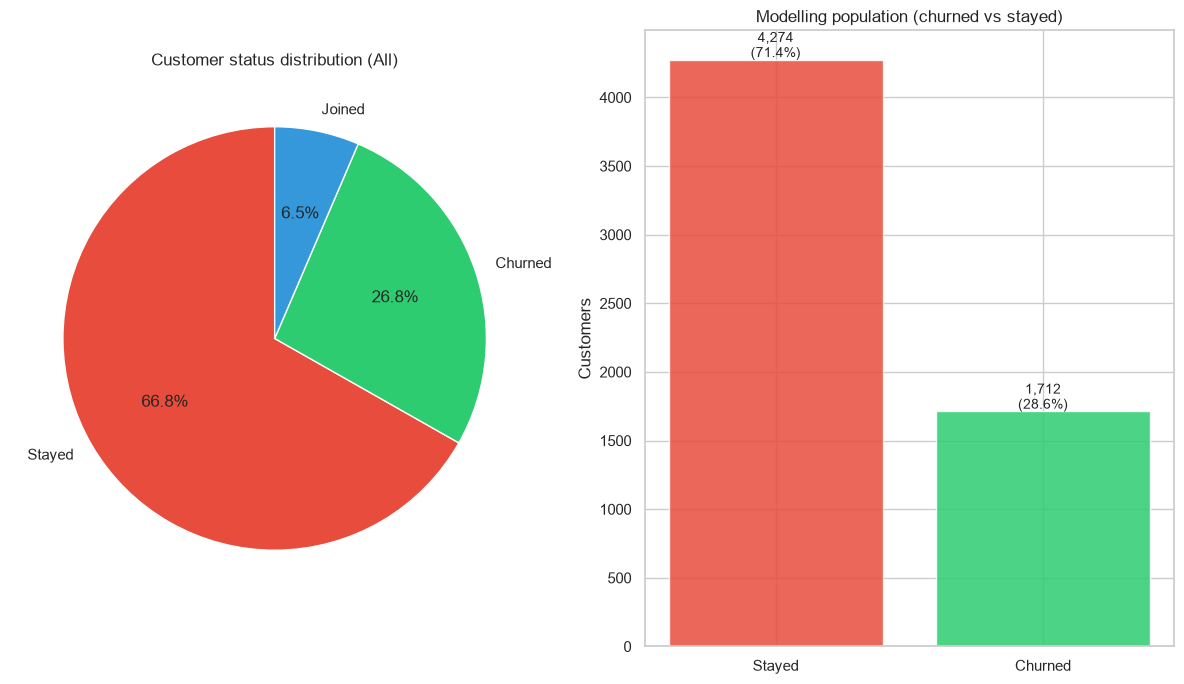

Churn rate (modelling pop): 28.6%


In [20]:
# Class distribution (all statuses)
fig, axes = plt.subplots(1, 2, figsize=(12, 7))

counts = df_all["customer_status"].value_counts()
axes[0].pie(counts, labels=counts.index, autopct="%1.1f%%",
            colors=["#e74c3c", "#2ecc71", "#3498db"], startangle=90)
axes[0].set_title("Customer status distribution (All)")

df_model = df_all[df_all["customer_status"].isin(["Churned", "Stayed"])].copy()
df_model["churn_label"] = (df_model["customer_status"] == "Churned").astype(int)

churn_counts = df_model["customer_status"].value_counts()
axes[1].bar(churn_counts.index, churn_counts.values,
            color=["#e74c3c", "#2ecc71"], alpha=0.85)
for i, (name, val) in enumerate(churn_counts.items()):
    axes[1].text(i, val + 20, f"{val:,}\n({val/len(df_model)*100:.1f}%)",
                ha="center", fontsize=10)
axes[1].set_title("Modelling population (churned vs stayed)")
axes[1].set_ylabel("Customers")

fig.tight_layout()
fig.savefig(FIGURES_DIR / "00_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Churn rate (modelling pop): {df_model['churn_label'].mean()*100:.1f}%")

### Finding: ~26% churn rate — moderate class imbalance. We'll use class_weight='balanced' in tree models and tune the decision threshold rather than relying on 0.5.

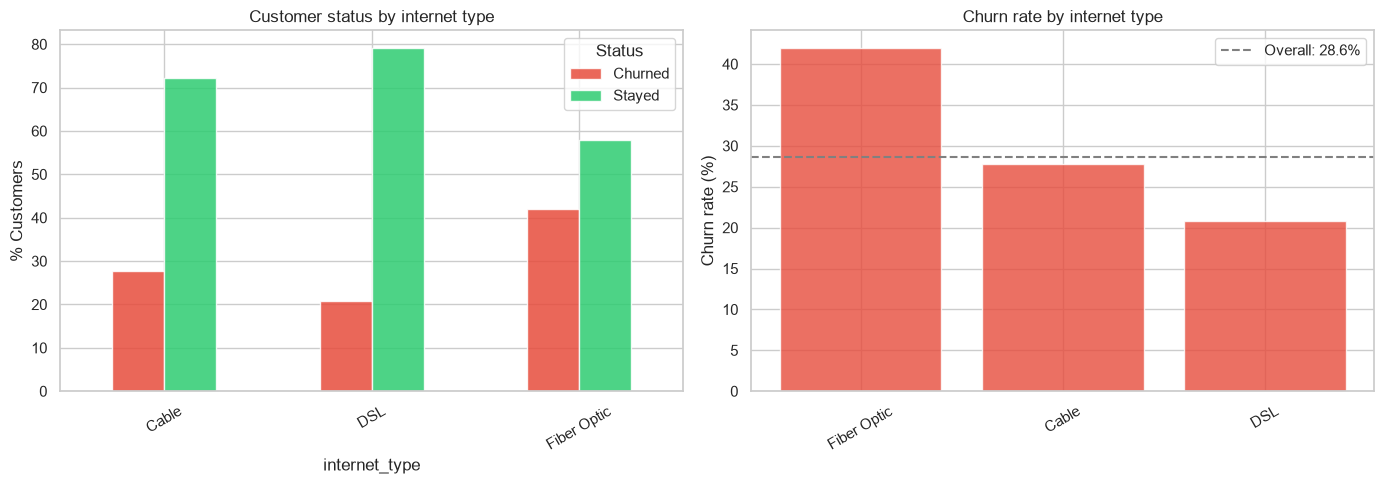

internet_type
Fiber Optic    0.420023
Cable          0.277311
DSL            0.207914


In [21]:
# Churn by internet type
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ct = pd.crosstab(df_model["internet_type"], df_model["customer_status"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100
ct_pct[["Churned", "Stayed"]].plot(
    kind="bar", ax=axes[0], color=["#e74c3c", "#2ecc71"], alpha=0.85
)
axes[0].set_title("Customer status by internet type")
axes[0].set_ylabel("% Customers")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(title="Status")

# Churn rate
churn_by_internet = df_model.groupby("internet_type")["churn_label"].mean().sort_values(ascending=False)
axes[1].bar(churn_by_internet.index, churn_by_internet.values * 100,
            color="#e74c3c", alpha=0.8)
axes[1].axhline(df_model["churn_label"].mean() * 100, color="grey", linestyle="--",
                label=f"Overall: {df_model['churn_label'].mean()*100:.1f}%")
axes[1].set_title("Churn rate by internet type")
axes[1].set_ylabel("Churn rate (%)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()

fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_internet_type_churn.png", dpi=150, bbox_inches="tight")
plt.show()
print(churn_by_internet.to_string())


### Finding:Fiber Optic customers churn at a ~40% rate — roughly 2× the overall rate. This aligns with competitive pressure in high-speed internet markets.

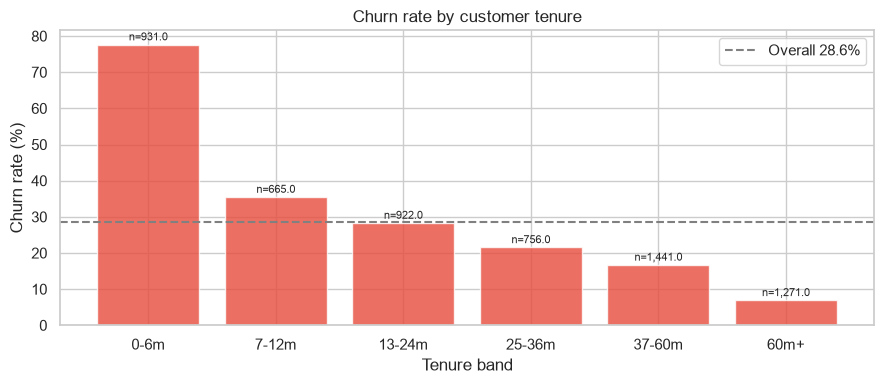

            churn_rate     n
tenure_bin                  
0-6m          0.776584   931
7-12m         0.354887   665
13-24m        0.283080   922
25-36m        0.215608   756
37-60m        0.167245  1441
60m+          0.069237  1271


In [23]:
# Churn by tenure
df_model["tenure_bin"] = pd.cut(
    df_model["tenure_in_months"],
    bins=[0, 6, 12, 24, 36, 60, np.inf],
    labels=["0-6m", "7-12m", "13-24m", "25-36m", "37-60m", "60m+"],
)
tenure_churn = df_model.groupby("tenure_bin", observed=True)["churn_label"].agg(["mean", "count"])
tenure_churn.columns = ["churn_rate", "n"]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(tenure_churn.index.astype(str), tenure_churn["churn_rate"] * 100,
              color="#e74c3c", alpha=0.8)
ax.axhline(df_model["churn_label"].mean() * 100, color="grey", linestyle="--",
           label=f"Overall {df_model['churn_label'].mean()*100:.1f}%")
for bar, (_, row) in zip(bars, tenure_churn.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"n={row['n']:,}", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("Tenure band")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by customer tenure")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_tenure_churn.png", dpi=150, bbox_inches="tight")
plt.show()
print(tenure_churn.to_string())


### Finding: Churn is heavily concentrated in the first 12 months (~50% churn rate), dropping sharply for long-tenured customers. Tenure is likely the strongest predictor.

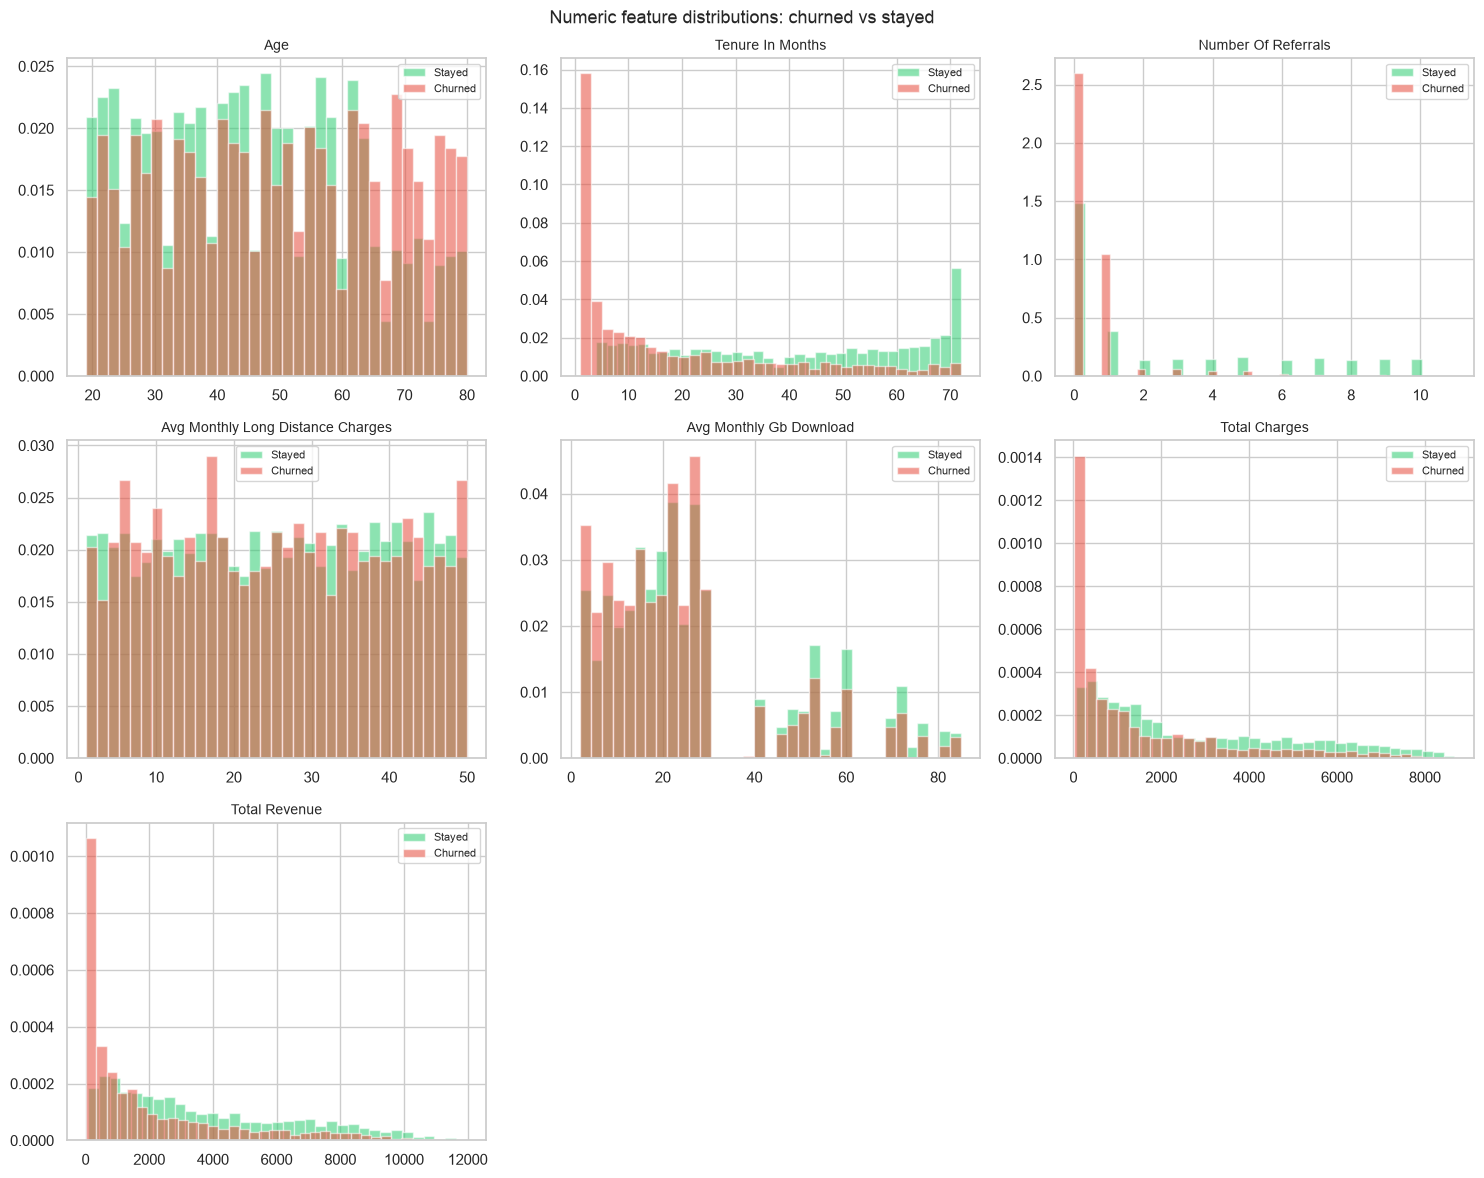

In [24]:
# Numeric distributions: churned vs stayed
num_cols = [
    "age", "tenure_in_months", "number_of_referrals",
    "avg_monthly_long_distance_charges", "avg_monthly_gb_download",
    "total_charges", "total_revenue",
]
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
palette = {"Churned": "#e74c3c", "Stayed": "#2ecc71"}

for i, col in enumerate(num_cols):
    ax = axes[i]
    for status in ["Stayed", "Churned"]:
        vals = df_model[df_model["customer_status"] == status][col].dropna()
        ax.hist(vals, bins=35, alpha=0.55, label=status, color=palette[status], density=True)
    ax.set_title(col.replace("_", " ").title(), fontsize=10)
    ax.legend(fontsize=8)

for j in range(len(num_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Numeric feature distributions: churned vs stayed", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_numeric_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

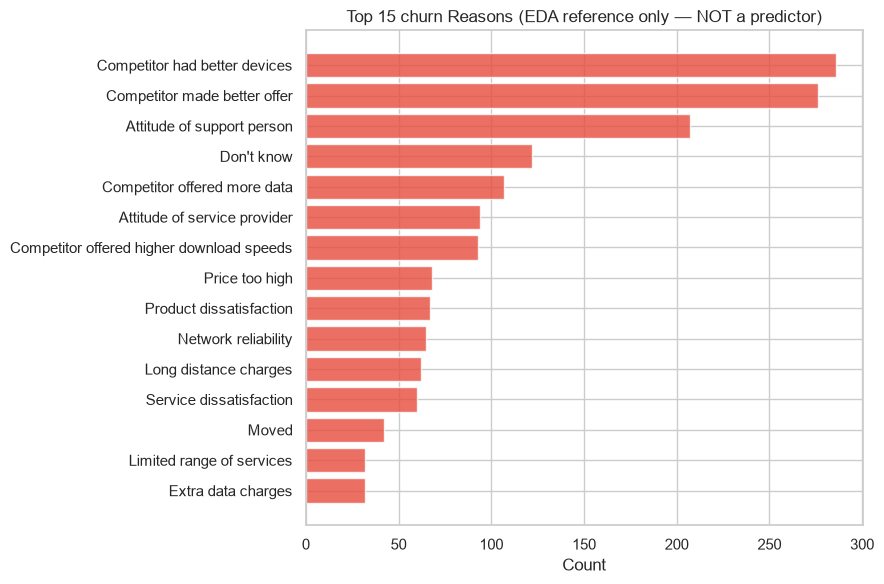

Top churn reasons:
churn_reason
Competitor had better devices                286
Competitor made better offer                 276
Attitude of support person                   207
Don't know                                   122
Competitor offered more data                 107
Attitude of service provider                  94
Competitor offered higher download speeds     93
Price too high                                68
Product dissatisfaction                       67
Network reliability                           65
Long distance charges                         62
Service dissatisfaction                       60
Moved                                         42
Limited range of services                     32
Extra data charges                            32


In [26]:
# Churn reasons (EDA only -- must NOT be used as features)
reason_counts = df_all[df_all["customer_status"] == "Churned"]["churn_reason"].value_counts().head(15)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(reason_counts.index, reason_counts.values, color="#e74c3c", alpha=0.8)
ax.set_xlabel("Count")
ax.set_title("Top 15 churn Reasons (EDA reference only — NOT a predictor)")
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_churn_reasons.png", dpi=150, bbox_inches="tight")
plt.show()
print("Top churn reasons:")
print(reason_counts.to_string())

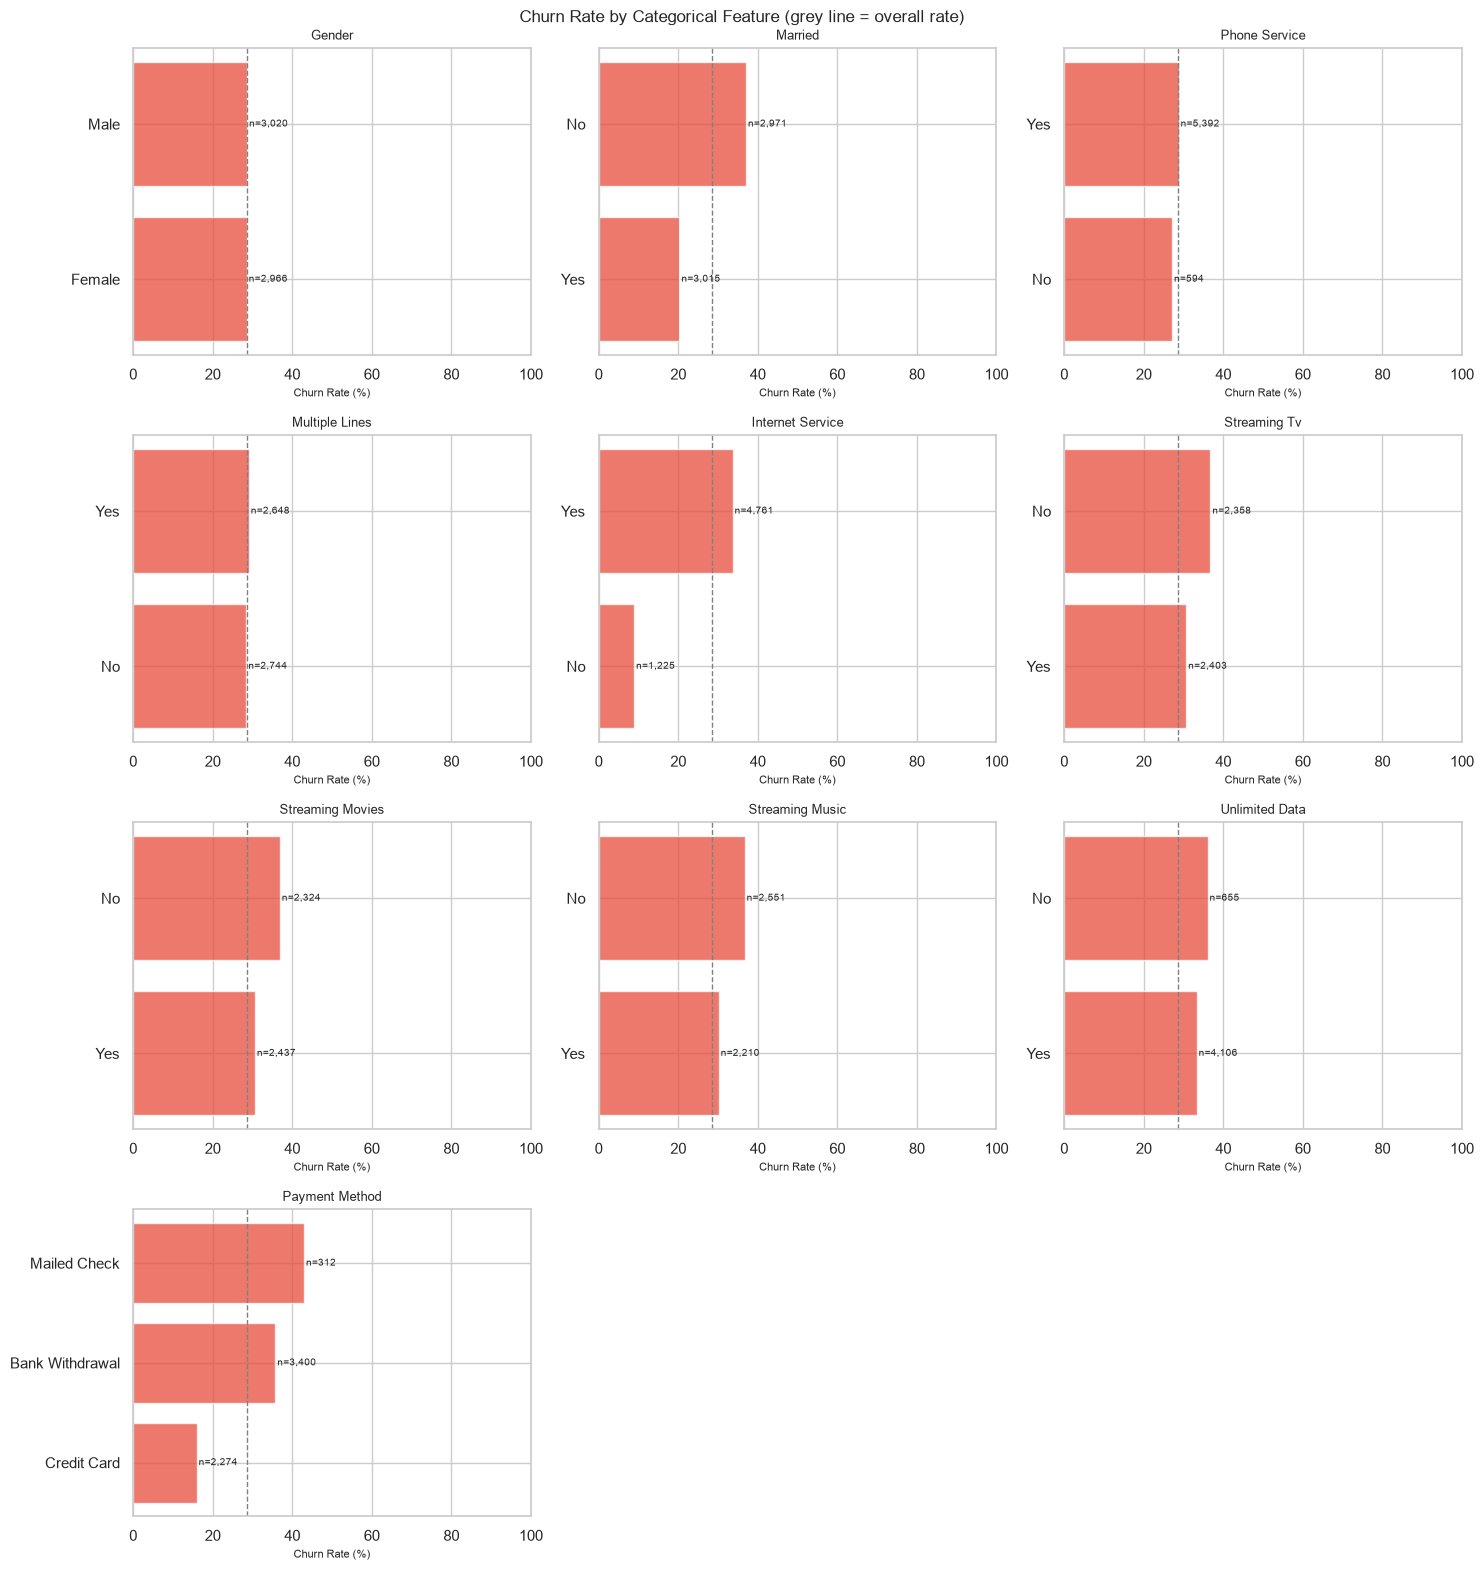

In [29]:
# Categorical churn rates
cat_cols = [
    "gender", "married", "phone_service", "multiple_lines",
    "internet_service", "streaming_tv", "streaming_movies",
    "streaming_music", "unlimited_data", "payment_method",
]
fig, axes = plt.subplots(4, 3, figsize=(15, 16))
axes = axes.flatten()

overall_rate = df_model["churn_label"].mean() * 100

for i, col in enumerate(cat_cols):
    summary = df_model.groupby(col)["churn_label"].agg(["mean", "count"])
    summary.columns = ["churn_rate", "n"]
    summary = summary.sort_values("churn_rate", ascending=True)
    ax = axes[i]
    bars = ax.barh(summary.index.astype(str), summary["churn_rate"] * 100,
                   color="#e74c3c", alpha=0.75)
    ax.axvline(overall_rate, color="grey", linestyle="--", linewidth=1)
    for bar, (_, row) in zip(bars, summary.iterrows()):
        ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
                f"n={int(row['n']):,}", va="center", fontsize=7)
    ax.set_title(col.replace("_", " ").title(), fontsize=9)
    ax.set_xlabel("Churn Rate (%)", fontsize=8)
    ax.set_xlim(0, 100)

for j in range(len(cat_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle("Churn Rate by Categorical Feature (grey line = overall rate)", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_categorical_churn_rates.png", dpi=150, bbox_inches="tight")
plt.show()

/var/folders/tf/g4zh87_57zv3517dtpgrm67r0000gn/T/ipykernel_9926/2857067087.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_enc.select_dtypes("object"):
/var/folders/tf/g4zh87_57zv3517dtpgrm67r0000gn/T/ipykernel_9926/2857067087.py:5: Pandas4Warning: 'ArrowStringArray' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  df_enc[col] = df_enc[col].map(bool_map).fillna(df_enc[col])
/var/folders/tf/g4zh87_57zv3517dtpgrm67r0000gn/T/ipykernel_9

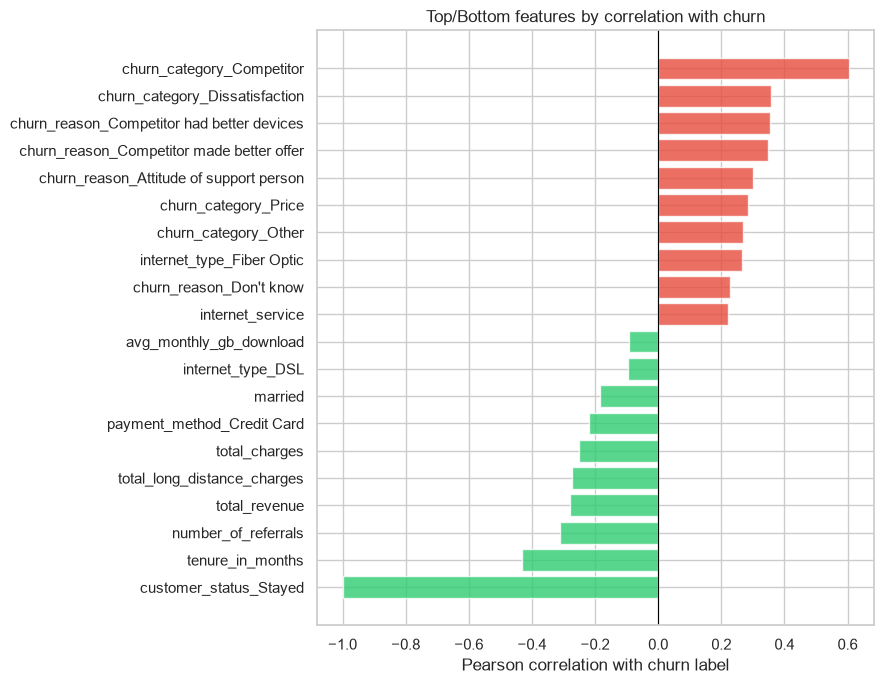

Top correlations with churn:
internet_service                              0.221156
churn_reason_Don't know                       0.227902
internet_type_Fiber Optic                     0.264961
churn_category_Other                          0.270133
churn_category_Price                          0.285295
churn_reason_Attitude of support person       0.299037
churn_reason_Competitor made better offer     0.347378
churn_reason_Competitor had better devices    0.353925
churn_category_Dissatisfaction                0.356516
churn_category_Competitor                     0.603450

Top negative correlations (churn protective):
customer_status_Stayed        -1.000000
tenure_in_months              -0.431927
number_of_referrals           -0.312282
total_revenue                 -0.279430
total_long_distance_charges   -0.272458
total_charges                 -0.249782
payment_method_Credit Card    -0.218878
married                       -0.185063
internet_type_DSL             -0.095031
avg_monthly_gb

In [31]:
# Correlation with churn label
df_enc = df_model.copy()
bool_map = {"Yes": 1, "No": 0, "Male": 1, "Female": 0}
for col in df_enc.select_dtypes("object"):
    df_enc[col] = df_enc[col].map(bool_map).fillna(df_enc[col])
df_enc = pd.get_dummies(df_enc.select_dtypes(include=["number", "object"]), drop_first=True)

corr = df_enc.corrwith(df_enc["churn_label"]).drop("churn_label").sort_values()
top_bottom = pd.concat([corr.head(10), corr.tail(10)])

fig, ax = plt.subplots(figsize=(9, 7))
colors = ["#e74c3c" if v > 0 else "#2ecc71" for v in top_bottom.values]
ax.barh(top_bottom.index, top_bottom.values, color=colors, alpha=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Pearson correlation with churn label")
ax.set_title("Top/Bottom features by correlation with churn")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "06_feature_correlation.png", dpi=150, bbox_inches="tight")
plt.show(fig)
print("Top correlations with churn:")
print(corr.tail(10).to_string())
print("\nTop negative correlations (churn protective):")
print(corr.head(10).to_string())

In [32]:
# Summary statistics for modeling population
print(f"Total customers: {len(df_model):,}")
print(f"Churned: {df_model['churn_label'].sum():,} ({df_model['churn_label'].mean()*100:.1f}%)")
print(f"Stayed: {(df_model['churn_label']==0).sum():,} ({(1-df_model['churn_label'].mean())*100:.1f}%)")
print(f"Joined (excluded): {(df_all['customer_status']=='Joined').sum():,}")
print("\nNumeric summary:")
print(df_model[[
    "age", "tenure_in_months", "number_of_referrals",
    "total_charges", "total_revenue", "avg_monthly_gb_download"
]].describe().round(2).to_string())

print("\nAll EDA figures saved to:", FIGURES_DIR)


Total customers: 5,986
Churned: 1,712 (28.6%)
Stayed: 4,274 (71.4%)
Joined (excluded): 413

Numeric summary:
           age  tenure_in_months  number_of_referrals  total_charges  total_revenue  avg_monthly_gb_download
count  5986.00           5986.00              5986.00        5986.00        5986.00                  4761.00
mean     46.82             34.40                 2.00        2425.92        3226.55                    26.25
std      16.87             24.01                 3.01        2268.99        2858.43                    19.62
min      19.00              1.00                 0.00          19.10          21.61                     2.00
25%      33.00             12.00                 0.00         533.67         825.37                    13.00
50%      46.00             32.00                 0.00        1549.20        2355.34                    21.00
75%      60.00             57.00                 3.00        3981.68        5094.86                    30.00
max      80.00     